In [541]:
from antares_devkit.models import BaseFilter
from antares_devkit.models import DevKitLocus
from antares_client import search
import numpy as np
import matplotlib.pyplot as plt
from astropy.time import Time
import pandas as pd
import math
from astropy.coordinates import Angle, SkyCoord
import astropy.units as u
import time
import warnings
import itertools
import pdb
from astropy.io import fits

fail_stats = {}

In [596]:
#extract data from lsst alert
def lsst_alert(alert):
    obs_date = float(alert.properties['lsst_diaSource_midpointMjdTai'])
    oid_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_scienceFlux']) + 31.4)
    temp_mag = float(-2.5*np.log10(alert.properties['lsst_diaSource_templateFlux']) + 31.4)
    diff_mag = float(temp_mag - oid_mag)
    
    bandpass = alert.properties['lsst_diaSource_band']
    band = 'lsst_' + str(bandpass)

    if alert.properties['lsst_diaSource_isNegative'] == True:
        pos_or_neg = -1
    else:
        pos_or_neg = 1
        
    return {band: [obs_date, oid_mag, temp_mag, diff_mag, pos_or_neg]}

def lsst_quality(alert):
    quality = True
    quality &= alert.properties['lsst_diaSource_reliability'] >= 0.6
    quality &= alert.properties['lsst_diaSource_psfFlux_flag'] == False
    quality &= alert.properties['lsst_diaSource_centroid_flag'] == False
    quality &= alert.properties['lsst_diaSource_shape_flag'] == False
    quality &= alert.properties['lsst_diaSource_isDipole'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_saturated'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_edge'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_cr'] == False
    quality &= alert.properties['lsst_diaSource_pixelFlags_streak'] == False
    quality &= alert.properties['lsst_diaSource_scienceFlux'] >= 0
    quality &= alert.properties['lsst_diaSource_templateFlux'] >= 0

    if 'lsst_diaSource_ssObjectId' in alert.properties:
        quality &= alert.properties['lsst_diaSource_ssObjectId'] in (0, None, "0")
    return quality

#extract data from ztf alert
#uses formula from 260609 6/15 markdown cell
def ztf_alert(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    temp_mag_err = alert.properties['ztf_sigmagnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    diff_img_mag_err = alert.properties['ztf_sigmapsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        pos_or_neg = -1
        m =  (1 - 10.**(0.4*(temp_mag - diff_img_mag)))
    else:
        pos_or_neg = 1
        m = (10.**(0.4*(temp_mag - diff_img_mag)) + 1)

    if m <= 0.01:
        diff_mag = 10**(-10)
    else:
        diff_mag = -2.5* np.log10(m)
    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])
    data = {'mjd': obs_date, 'band': band, 'm_sci': oid_mag, 'm_template': temp_mag, 'm_diff': diff_img_mag, 
            'delta_m': diff_mag, 'pos_or_neg': pos_or_neg}
    return data

def ztf_alert2(alert):
    bands = ['x', 'g', 'R', 'i']
    
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    temp_mag_err = alert.properties['ztf_sigmagnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    diff_img_mag_err = alert.properties['ztf_sigmapsf']
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        pos_or_neg = -1
    else:
        pos_or_neg = 1

    oid_mag = -2.5*np.log(10**(-0.4*temp_mag) + pos_or_neg*10**(-0.4*diff_img_mag))
    diff_mag = abs(oid_mag - temp_mag)
    band = 'ztf_' + str(bands[band_id])
    data = {'mjd': obs_date, 'band': band, 'm_sci': oid_mag, 'm_template': temp_mag, 'm_diff': diff_img_mag, 
            'delta_m': diff_mag, 'pos_or_neg': pos_or_neg}
    return data

def ztf_alert_err(alert):
    bands = ['x', 'g', 'R', 'i']
    band_id = alert.properties['ztf_fid']
    obs_date = float(alert.properties['ant_mjd'])
    ant_mag = alert.properties['ant_mag']
    temp_mag = alert.properties['ztf_magnr']
    temp_mag_err = alert.properties['ztf_sigmagnr']
    diff_img_mag = alert.properties['ztf_magpsf']
    diff_img_mag_err = alert.properties['ztf_sigmapsf']
    n = 10.**(0.4*(temp_mag - diff_img_mag))
    flag = 0
    
    if alert.properties['ztf_isdiffpos'] == 'f' or alert.properties['ztf_isdiffpos'] == 0:
        pos_or_neg = -1
        if 1-n <= 0.:
            diff_mag = 10**(-10)
            oid_mag_err = np.sqrt( 2**2 *temp_mag_err**2 + diff_img_mag_err**2 )
            flag = 1
        else:
            diff_mag = -2.5* np.log10(1-n)
            oid_mag_err = np.sqrt( (1+n/(1-n))**2 * temp_mag_err**2 + (-n/(1-n))**2 * diff_img_mag_err**2 )
    else:
        pos_or_neg = 1
        if 1+n <= 0.:
            diff_mag = 10**(-10)
            oid_mag_err = np.sqrt( 2**2 * temp_mag_err**2 + diff_img_mag_err**2 )
            flag = 1
        else:
            diff_mag = -2.5* np.log10(1+n)
            oid_mag_err = np.sqrt( (1-n/(1+n))**2 * temp_mag_err**2 + (n/(1+n))**2 * diff_img_mag_err**2 )
    oid_mag = diff_mag + temp_mag
    band = 'ztf_' + str(bands[band_id])

    data = {'mjd': obs_date, 'band': band, 'm_sci': oid_mag, 'm_sci_err': oid_mag_err, 'm_template': temp_mag, 'm_template_err': temp_mag_err, 
            'm_diff': diff_img_mag, 'm_diff_err': diff_img_mag_err, 'delta_m': diff_mag, 'pos_or_neg': pos_or_neg, 'm_sci_flag': flag}
    # data = pd.DataFrame(data=[[obs_date], [oid_mag], [oid_mag_err], [temp_mag], [temp_mag_err], [diff_img_mag], [diff_img_mag_err], [diff_mag], [pos_or_neg]], 
    #                                 columns = ['mjd', 'm_sci', 'm_sci_err', 'm_template', 'm_template_err', 'm_diff', 'm_diff_err', 'delta_m', 'pos_or_neg'])
    return data


#checks ztf alert for good quality
def ztf_quality(alert):
    quality = True
    quality &= alert.properties['ztf_rb'] >= 0.65
    quality &= alert.properties['ztf_nbad'] == 0
    quality &= alert.properties['ztf_fwhm'] <= 5
    quality &= alert.properties['ztf_elong'] <= 1.2
    quality &= abs(alert.properties['ztf_magdiff']) <= 1.
    return quality

#unpacks all alerts (that pass a quality test)
def oid_get_info(alerts):

    #snr check
    new_alert = alerts[-1]

    if new_alert.properties['ant_survey'] == 1:
        if (1.0857/new_alert.properties['ztf_sigmapsf']) < 8:
            return 'snr too low'
        elif ztf_quality(new_alert) == True:
            oid = ztf_alert_err(new_alert)
        else:
            return 'failed ztf quality check'
    else:
        return 'alert not applicable'
            
    return oid

def var_params(oid, make_targets = False):
    vp = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
               'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    data_lim = 0
    for band in oid:
        if band == 'locus':
            continue
        if isinstance(oid[band], pd.DataFrame) == 0:
            data_lim += 1
            continue
        if len(oid[band]) < 3:
            data_lim += 1
            vp[band] = {'diff_mag':0, 'var':0, 'hyper_v':0, 'data':oid[band]}
        
        max_mjd_i = oid[band].mjd.idxmax()
        diff_mag = float(oid[band]['diff_mag'][max_mjd_i])
        var = np.var(oid[band]['oid_mag'])
        # hv = float(np.sqrt(diff_mag ** 2 + (coeff * var) ** 2))
        # vp[band] = {'diff_mag':diff_mag, 'var':var, 'hyper_v':hv, 'data':oid[band]}
        vp[band] = {'diff_mag':diff_mag, 'var':var, 'data':oid[band]}

    # if make_targets == True:
        
    if data_lim == 9:
        return 0
    else: 
        return vp

def catalog_check(locus):
    flags = {'known_star': False, 'known_agn': False, 'known_galaxy': False, 'gaia_likely_star': False, 
                            'gaia_astro_star': False, 'ps1_pointlike': False}
    for cat in locus.catalog_objects:
        if cat == 'asassn_variable_catalog' or cat == 'asassn_variable_Catalog_v2_20190802' or cat == 'sdss_stars':
            flags['known_star'] = True
        if cat == 'veron_agn_qso' or cat == 'milliquas':
            flags['known_agn'] = True
        if cat == '2mass_xsc' or cat == 'nyu_valueadded_gals' or cat == 'sdss_gals' or cat == 'RC3':
            flags['known_galaxy'] = True
        if cat == 'gaia_dr3_gaia_source':
            if isinstance(locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'], float) == 1 and locus.catalog_objects[cat][0]['classprob_dsc_combmod_star'] > 0.5:
                flags['gaia_likely_star'] = True
            if isinstance(locus.catalog_objects[cat][0]['parallax'], float) == 1:
                gdr3_check1 = (locus.catalog_objects[cat][0]['parallax'] + 0.017)/locus.catalog_objects[cat][0]['parallax_error']
                alpha = locus.catalog_objects[cat][0]['pmra']/locus.catalog_objects[cat][0]['pmra_error']
                beta = locus.catalog_objects[cat][0]['pmdec']/locus.catalog_objects[cat][0]['pmdec_error']
                gamma = locus.catalog_objects[cat][0]['pmra_pmdec_corr']
                gdr3_check2 = np.sqrt((alpha**2 + beta**2 -2*alpha*beta*gamma)/(1 - gamma**2))
                if gdr3_check1 > 5 or gdr3_check2 > 5:
                    flags['gaia_astro_star'] = True
        alert_temp = locus.alerts[-1].properties
        if alert_temp['ant_survey'] == 1 and ((alert_temp['ztf_sgscore1'] > 0.5 and alert_temp['ztf_distpsnr1'] < 1) or (alert_temp['ztf_sgscore2'] > 0.5 and alert_temp['ztf_distpsnr2'] < 1) or (alert_temp['ztf_sgscore3'] > 0.5 and alert_temp['ztf_distpsnr3'] < 1)):
            flags['ps1_pointlike'] = True
    return flags

def query_by_chunk(mjd_start, mjd_end, ra_min, ra_max, dec_min, dec_max,
                   faint_lim=21, min_ndet=3, max_results=10000,
                   retries=3, wait=180):
    # set the query to fetch loci with alerts matching search criteria
    query = {
        "query": {
            "bool": {
                "filter": [
                    { "range": { "properties.newest_alert_observation_time": { "gte": mjd_start, "lte": mjd_end} } },
                    { "range": { "properties.brightest_alert_magnitude": {"lte": faint_lim} } },
                    { "range": { "properties.num_mag_values" : { "gte": 3} } },
                    { "range": { "ra": { "gte": ra_min, "lte": ra_max} } },
                    { "range": { "dec": { "gte": dec_min, "lte": dec_max} } }
                      ]
            }
        }
    }

    # sometimes the ANTARES server times out so try a few times
    # before giving up and returning an empty list (to avoid crashing the entire query)
    for attempt in range(retries):
        try:
            loci = list(search.search(query))
            if len(loci) >= max_results:
                warnings.warn(
                    f'Chunk MJD {mjd_start:.1f}–{mjd_end:.1f} hit the {max_results}-result max.'
                    f'— Reduce QUERY_DT or this window is incomplete.',
                    stacklevel=2
                )
            return get_ids(loci)
        except Exception as e:
            if attempt < retries - 1:
                print(f'  Chunk {mjd_start}–{mjd_end} failed (attempt {attempt+1}/{retries}): {e}.')
                time.sleep(15)
            else:
                time.sleep(wait)
                # pdb.set_trace()
                attempt = 0

def get_ids(loci):
    # print(loci)
    loci_ids = []
    for locus in loci:
        loci_ids.append(locus.locus_id)
    return loci_ids


def get_target_info(locus, oid):
    
    target = pd.DataFrame(columns = ['too_id','fiber_type','catalogid','sdss_id','gaia_dr3_source_id',
                                     'twomass_pts_key','sky_brightness_mode','ra','dec','pmra','pmdec',
                                     'epoch','parallax','lambda_eff','u_mag','g_mag','r_mag','i_mag','z_mag',
                                     'optical_prov','gaia_bp_mag','gaia_rp_mag','gaia_g_mag','h_mag',
                                     'delta_ra','delta_dec','can_offset','inertial','n_exposures','priority',
                                     'active','expiration_date','observed'])
    target.loc[0,'fiber_type'] = 'BOSS'
    for cat in locus.catalog_objects:
        if cat == 'sdss_gals':
            target.loc[0,'sdss_id'] = locus.catalog_objects[cat][0]['Objid']
        elif cat == 'sdss_stars':
            target.loc[0,'sdss_id'] = locus.catalog_objects[cat][0]['Objid']
        elif cat == 'gaia_dr3_gaia_source':
            target.loc[0,'gaia_dr3_source_id'] = locus.catalog_objects[cat][0]['Source Id']
        elif cat == '2mass_xsc':
            target.loc[0,'twomass_pts_key']= locus.catalog_objects[cat][0]['Id']

    target.loc[0,'sky_brightness_mode'] = 'dark'
    target.loc[0, 'ra'] = locus.ra
    target.loc[0,'dec'] = locus.dec

    
    passband = locus.alerts[-1].properties['ant_passband']
    if locus.alerts[-1].properties['ant_survey'] == 4: #lsst
        if passband == 'y':
            a  = 1
        else:
            target[passband+'_mag'].loc[0] = oid['lsst_'+passband]
    elif locus.alerts[-1].properties['ant_survey'] == 1:
        if passband == 'R':
            target.loc[0,'r_mag'] = oid['ztf_R']
        else:
            target.loc[0,passband+'_mag'] = oid['ztf_'+passband]

    target.loc[0, 'can_offset'] = True
    target.loc[0, 'n_exposures'] = 3
    target.loc[0, 'priority'] = 5
    target.loc[0, 'active'] = True
    target.loc[0, 'observed'] = False
    
    return target


def lightcurve(alerts):
    # lc = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
    #      'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    lc = 0
    flag = 0
    for alert in alerts:
        # if alert.properties['ant_survey'] == 4:
        #     comp = lsst_alert(alert)
        if alert.properties['ant_survey'] == 1:
            data = ztf_alert_err(alert)
        else:
            continue
        
        # if isinstance(lc, int) == 1:
        #     lc[band] = pd.DataFrame(data, index=[0])
        # else:
        #     h = pd.DataFrame(data, index=[-1])
        #     lc[band] = pd.concat([lc[band], h]).reset_index(drop=True)

        if isinstance(lc, int) == 1:
            lc = pd.DataFrame(data, index=[0])
        else:
            h = pd.DataFrame(data, index=[-1])
            lc = pd.concat([lc, h]).reset_index(drop=True)
        
    return lc

def lightcurve_quality(alerts):
    # lc = {'lsst_g': 0, 'lsst_r': 0, 'lsst_i': 0, 'lsst_z': 0, 'lsst_u': 0, 'lsst_y': 0, 
    #      'ztf_g': 0, 'ztf_R': 0, 'ztf_i': 0}
    lc = 0
    # flag = 0
    for alert in alerts:
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                data = ztf_alert_err(alert)
            else:
                continue
        else:
            continue
        
        if isinstance(lc, int) == 1:
            lc = pd.DataFrame(data, index=[0])
        else:
            h = pd.DataFrame(data, index=[-1])
            lc = pd.concat([lc, h]).reset_index(drop=True)
    return lc

def lightcurve_quality2(alerts):
    lc = 0
    lc2 = 0
    for alert in alerts:
        if alert.properties['ant_survey'] == 4:
            lsst_pass = lsst_quality(alert)
            if lsst_pass == True:
                comp = lsst_alert(alert)
            else:
                continue
        elif alert.properties['ant_survey'] == 1:
            ztf_pass = ztf_quality(alert)
            if ztf_pass == True:
                data = ztf_alert_err(alert)
                data2 = ztf_alert2(alert)
            else:
                continue
        else:
            continue
        
        if isinstance(lc, int) == 1:
            lc = pd.DataFrame(data, index=[0])
        else:
            h = pd.DataFrame(data, index=[-1])
            lc = pd.concat([lc, h]).reset_index(drop=True)
            
        if isinstance(lc2, int) == 1:
            lc2 = pd.DataFrame(data2, index=[0])
        else:
            h = pd.DataFrame(data2, index=[-1])
            lc2 = pd.concat([lc2, h]).reset_index(drop=True)
    return lc, lc2

def plot_lc2(oid_id):
    colors = {'ztf_g': 'green', 'ztf_R': 'orangered', 'ztf_i': 'black'}
    fig, ax = plt.subplots(1,2, figsize=(10,4), sharey=False)
    
    locus = search.get_by_id(oid_id)
    lc = lightcurve(locus.alerts)
    lc_q = lightcurve_quality(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '

    data_lc[oid_id] = lc
    data_lc_q[oid_id] = lc_q
    empty = 0
    empty_q = 0
    
    for band in colors:
        band_data = lc[(lc['band'] == band)]
        band_data_q = lc_q[(lc_q['band'] == band)]
        if len(band_data) > 2:
            ax[0].errorbar(band_data['mjd'], band_data['m_sci'], yerr=band_data['m_sci_err'], fmt='.', ms=2, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.5)
            ax[0].hlines(y=np.average(band_data['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                          colors = colors[band], alpha = 0.3, ls = '--')
        else:
            empty += 1
        if len(band_data_q) > 2:
            ax[1].errorbar(band_data_q['mjd'], band_data_q['m_sci'], yerr=band_data_q['m_sci_err'], fmt='.', ms=2, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.5)
            ax[1].hlines(y=np.average(band_data_q['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                          colors = colors[band], alpha = 0.3, ls = '--')
        else:
            empty_q += 1
    
    if empty == 3:
        print(f'{oid_id}: not enough data')
        plt.close()
    else:
        flags = catalog_check(locus)
        for flag in flags:
            if flags[flag] == True and len(flags_str) == 7:
                flags_str += flag
            elif flags[flag] == True:
                flags_str += ', ' + flag
        if len(min_lc) > 0 and len(max_lc) > 0:
            ax[0].set(ylim=(min(lc['m_sci'])-0.5, max(lc['m_sci'])+0.5))
        if len(min_lc_q) > 0 and len(max_lc_q) > 0:
            ax[1].set(ylim=(min(lc_q['m_sci'])-0.5, max(lc_q['m_sci'])+0.5))
        ax[0].yaxis.set_inverted(True)
        ax[1].yaxis.set_inverted(True)
        ax[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    
        if len(flags_str) > 7:
            fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(flag_n) + ', ' + str(flag_nq), fontname = 'serif')
        else:
            fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(flag_n) + ', ' + str(flag_nq), fontname = 'serif')
        plt.xlabel('MJD', fontname = 'serif')
        ax[0].set_ylabel('$mag_{AB}$', fontname = 'serif')
        ax[1].set_ylabel('$mag_{AB}$', fontname = 'serif')
        ax[0].grid(alpha=0.25)
        ax[1].grid(alpha=0.25)
        plt.tight_layout()

def plot_lc(oid_id):
    colors = {'ztf_g': 'green', 'ztf_R': 'orangered', 'ztf_i': 'black'}
    fig, ax = plt.subplots(1,1, figsize=(9,6))
    
    locus = search.get_by_id(oid_id)
    lc = lightcurve_quality(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '

    empty = 0
    empty_q = 0
    
    for band in colors:
        band_data = lc[(lc['band'] == band)]
        if len(band_data) > 2:
            ax.errorbar(band_data['mjd'], band_data['m_sci'], yerr=band_data['m_sci_err'], fmt='.', ms=2, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.5)
            ax.hlines(y=np.average(band_data['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                          colors = colors[band], alpha = 0.3, ls = '--')
        else:
            empty += 1
            
    if empty == 3:
        print(f'{oid_id}: not enough data')
        plt.close()
    else:
        flags = catalog_check(locus)
        for flag in flags:
            if flags[flag] == True and len(flags_str) == 7:
                flags_str += flag
            elif flags[flag] == True:
                flags_str += ', ' + flag
        ax.set(ylim=(min(lc['m_sci'])-0.5, max(lc['m_sci'])+0.5))
        ax.yaxis.set_inverted(True)
        ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    
        if len(flags_str) > 7:
            fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(flag_n), fontname = 'serif')
        else:
            fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(flag_n), fontname = 'serif')
        plt.xlabel('MJD', fontname = 'serif')
        ax.set_ylabel('$mag_{AB}$', fontname = 'serif')
        ax.grid(alpha=0.25)
        plt.tight_layout()

In [264]:
targets = pd.DataFrame(columns = ['too_id','fiber_type','catalogid','sdss_id','gaia_dr3_source_id',
                                 'twomass_pts_key','sky_brightness_mode','ra','dec','pmra','pmdec',
                                 'epoch','parallax','lambda_eff','u_mag','g_mag','r_mag','i_mag','z_mag',
                                 'optical_prov','gaia_bp_mag','gaia_rp_mag','gaia_g_mag','h_mag',
                                 'delta_ra','delta_dec','can_offset','inertial','n_exposures','priority',
                                 'active','expiration_date','observed'])
stats_now = {'snr':0, 'recency':0, 'trig_a_quality':0, 'faint':0, 'data_limitted':0,'variable':0,'checked':0}

oid_sample = {}

In [ ]:

ra_s = np.arange(0, 360, 10)
dec_s = np.arange(-40, 40, 10)

t_now = Time.now().mjd
oids = {'id': [], 'mjd': [], 'band': [], 'm_sci': [], 'm_sci_err': [], 'm_template': [], 'm_template_err': [], 
            'm_diff': [], 'm_diff_err': [], 'delta_m': [], 'pos_or_neg': [], 'm_sci_flag': []}
oids = pd.DataFrame(oids)
       
for ra, dec in list(itertools.product(ra_s, dec_s)):
    RA_MIN = float(ra)
    RA_MAX = float(RA_MIN + 10)
    DEC_MIN = float(dec)
    DEC_MAX = float(DEC_MIN + 10)
    
    loci_ids = query_by_chunk(t_now-1, t_now, RA_MIN, RA_MAX, DEC_MIN, DEC_MAX)
    print(f'({RA_MIN} - {RA_MAX}, {DEC_MIN} - {DEC_MAX}) : {len(loci_ids)}')
    
    for l_id in loci_ids:
        locus = search.get_by_id(l_id)
        # oid_dv = locus.to_devkit()
        oid_locus = DevKitLocus.model_validate(locus.to_devkit())
        # id_here = pd.DataFrame({'ids':l_id})
        oid_here = oid_get_info(oid_locus.alerts)
        if isinstance(oid_here, str):
            continue
        else:
            oid_here['id'] = [l_id]
            oid_here = pd.DataFrame(oid_here, index = [-1])
            oids = pd.concat([oids, oid_here]).reset_index(drop=True)
oids.to_csv(f'query_data/{int(t_now)}.csv')

(0.0 - 10.0, -40.0 - -30.0) : 0
(0.0 - 10.0, -30.0 - -20.0) : 82


In [399]:
oid_ids = ['ANT2018gxcyw', 'ANT2020nbnwa', 'ANT2019vvhlq', 'ANT2020k6qqo']
too_dark_oids = ['ANT2018gxcyw', 'ANT2020nbnwa']
# data_lc = {}
# data_lc_q = {}

error propagation math:
$$ p/n = -1$$ 
$$m_{sci} = -2.5log\left(1-10^{0.4(m_{template} - m_{diff})}\right) + m_{template}$$
$$\sigma_{m\_sci}^2 = \left(\frac{\partial m_{template}}{\partial m_{sci}}\right)^2 \sigma_{m\_template} ^2 + \left(\frac{\partial m_{diff}}{\partial m_{sci}}\right)^2 \sigma_{m\_diff} ^2 $$
$$\sigma_{m\_sci}^2 = \left(\frac{10^{0.4(m_{template}-m_{diff})}}{1-10^{0.4(m_{template}-m_{diff})}}+1\right)^2 \sigma_{m\_template} ^2 + 
\left(\frac{-10^{0.4(m_{template}-m_{diff})}}{1-10^{0.4(m_{template}-m_{diff})}}\right)^2 \sigma_{m\_template} ^2 $$

$$ p/n = 1$$ 
$$m_{sci} = -2.5log\left(1+10^{0.4(m_{template} - m_{diff})}\right) + m_{template}$$
$$\sigma_{m\_sci}^2 = \left(\frac{\partial m_{template}}{\partial m_{sci}}\right)^2 \sigma_{m\_template} ^2 + \left(\frac{\partial m_{diff}}{\partial m_{sci}}\right)^2 \sigma_{m\_diff} ^2 $$
$$\sigma_{m\_sci}^2 = \left(\frac{-10^{0.4(m_{template}-m_{diff})}}{1+10^{0.4(m_{template}-m_{diff})}}+1\right)^2 \sigma_{m\_template} ^2 + 
\left(\frac{10^{0.4(m_{template}-m_{diff})}}{1+10^{0.4(m_{template}-m_{diff})}}\right)^2 \sigma_{m\_template} ^2 $$

In [122]:
data_lc_q

{'ANT2018gxcyw': {'lsst_g': 0,
  'lsst_r': 0,
  'lsst_i': 0,
  'lsst_z': 0,
  'lsst_u': 0,
  'lsst_y': 0,
  'ztf_g':               mjd      m_sci  m_sci_err  m_template  m_template_err  \
  0    58369.327569  19.949069   0.290131   18.316999           0.028   
  1    58372.397326  18.223661   0.049478   18.801001           0.027   
  2    58372.398704  20.084029   0.325312   18.316999           0.028   
  3    58375.418357  20.334377   0.361121   18.801001           0.027   
  4    58375.419271  20.107365   0.368410   18.316999           0.028   
  ..            ...        ...        ...         ...             ...   
  365  61314.224664  18.316999   0.107501   18.316999           0.028   
  366  61315.314143  21.654026   1.845690   18.801001           0.027   
  367  61316.325347  22.184511   2.458237   18.316999           0.028   
  368  61317.334583  21.718078   1.948893   18.316999           0.028   
  369  61318.271366  21.459365   1.261606   18.316999           0.028   
  
      

In [121]:
check1a = data_lc_q['ANT2018gxcyw']['ztf_R'].loc[255]
check1b = data_lc_q['ANT2018gxcyw']['ztf_R'].loc[256]
check2a = data_lc_q['ANT2020nbnwa']['ztf_g'].loc[118]
check2b = data_lc_q['ANT2020nbnwa']['ztf_g'].loc[119]
print(f'ANT2018gxcyw\n{check1a}\n{check1b}\n\nANT2020nbnwa\n{check2a}\n{check2b}')

ANT2018gxcyw
mjd               61314.334641
m_sci                23.123604
m_sci_err             5.965098
m_template           18.494999
m_template_err        0.029000
m_diff               18.510393
m_diff_err            0.079939
delta_m               4.628605
pos_or_neg           -1.000000
Name: 255, dtype: float64
mjd               61315.272095
m_sci                21.387768
m_sci_err             1.186425
m_template           18.494999
m_template_err        0.029000
m_diff               18.573378
m_diff_err            0.083165
delta_m               2.892770
pos_or_neg           -1.000000
Name: 256, dtype: float64

ANT2020nbnwa
mjd               61312.335035
m_sci                23.032627
m_sci_err            10.495163
m_template           18.344000
m_template_err        0.017000
m_diff               18.358561
m_diff_err            0.140646
delta_m               4.688627
pos_or_neg           -1.000000
Name: 118, dtype: float64
mjd               61316.325347
m_sci                20.186

In [64]:
a = [check1, check2]
for check in a:
    # print(check)
    n = 10**(0.4*(check['m_template'] - check['m_diff'])) 
    dmdtemp = n/(1-n) + 1
    dmddiff = -n/(1-n)
    sigma_m = np.sqrt(dmdtemp**2 * check['m_template_err']**2 + dmddiff**2 * check['m_diff_err']**2)
    print(sigma_m, n, dmdtemp, check['m_template_err'], dmddiff, check['m_diff_err'])

5.965098090789491 0.9859214507202615 71.03004579024167 0.028999999165534973 -70.03004579024167 0.07993931323289871
10.49516321516477 0.9866786256536023 75.06732969113027 0.017000000923871994 -74.06732969113027 0.14064620435237885


In [87]:
for oid_id in oid_ids:
    for band in data_lc_q[oid_id]:
        if isinstance(data_lc_q[oid_id][band], int) == 1:
            continue

        i = 0
        while i < len(data_lc_q[oid_id][band]):
            if data_lc_q[oid_id][band].loc[i]['pos_or_neg'] != -1:
                i += 1
                continue
            check = data_lc_q[oid_id][band].loc[i]
            # n = 10**(0.4*(data_lc_q[oid_id][band].loc[i]['m_template'] - data_lc_q[oid_id][band].loc[i]['m_diff'])) 
            # print(oid_id, band, n, data_lc_q[oid_id][band].loc[i]['m_sci'], data_lc_q[oid_id][band].loc[i]['m_sci_err'])
            n = 10**(0.4*(check['m_template'] - check['m_diff'])) 
            dmdtemp = n/(1-n) + 1
            dmddiff = -n/(1-n)
            sigma_m = np.sqrt(dmdtemp**2 * check['m_template_err']**2 + dmddiff**2 * check['m_diff_err']**2)
            print(oid_id, band, sigma_m, check['m_sci_err'], check['m_sci'], n, dmdtemp, check['m_template_err'], dmddiff, check['m_diff_err'])

            i += 1

ANT2018gxcyw ztf_g 0.2901311736616746 0.2901311736616746 19.949068889137127 0.7775808285903881 4.496015310471501 0.02800000086426735 -3.4960153104715004 0.07476987689733505
ANT2018gxcyw ztf_g 0.3253115133359684 0.3253115133359684 20.084029182501197 0.8035789170442912 5.091103179720738 0.02800000086426735 -4.091103179720738 0.07147595286369324
ANT2018gxcyw ztf_g 0.3611206492189176 0.3611206492189176 20.334377317840644 0.7564156898561861 4.105354730810014 0.027000000700354576 -3.105354730810014 0.11067599803209305
ANT2018gxcyw ztf_g 0.368410287050757 0.368410287050757 20.107365093023898 0.807755582682471 5.201711518874985 0.02800000086426735 -4.201711518874985 0.08053799718618393
ANT2018gxcyw ztf_g 0.29491771333724803 0.29491771333724803 20.306893065992824 0.7501709067897706 4.002736379299536 0.027000000700354576 -3.0027363792995363 0.09138400107622147
ANT2018gxcyw ztf_g 0.3231940125552669 0.3231940125552669 20.217764913191868 0.8263423943040765 5.758457834268496 0.02800000086426735 -4.7

In [78]:
ns = {}

for oid_id in oid_ids:
    here = {}
    for band in data_lc_q[oid_id]:
        if isinstance(data_lc_q[oid_id][band], int) == 1:
            continue
        here[band] = [10**(0.4*(data_lc_q[oid_id][band]['m_template'] - data_lc_q[oid_id][band]['m_diff']))]
    ns[oid_id] = here

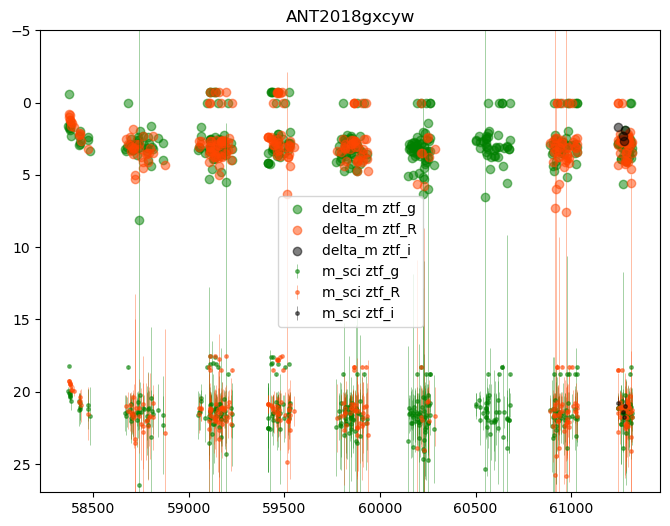

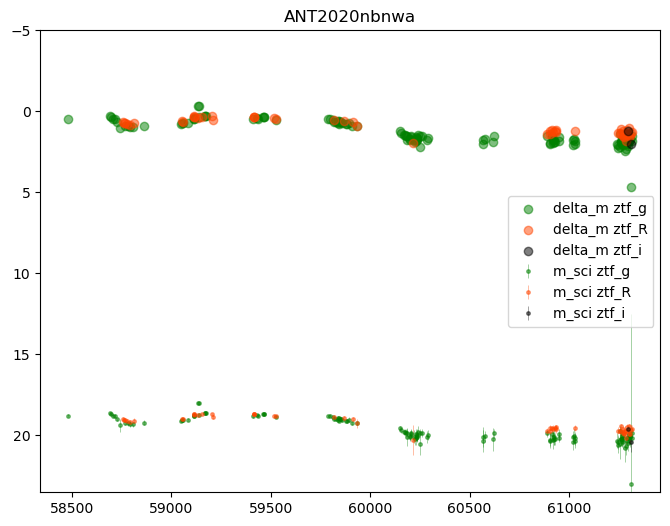

In [118]:
for oid_id in data_lc_q:
    fig, ax = plt.subplots(figsize = (8,6))
    a = []
    b = []
    for band in data_lc_q[oid_id]:
        if isinstance(data_lc_q[oid_id][band], int) == 1:
            continue
        ax.errorbar(data_lc_q[oid_id][band]['mjd'], data_lc_q[oid_id][band]['m_sci'], data_lc_q[oid_id][band]['m_sci_err'],  fmt='.', ms=5, lw=0.5, c = colors[band], ecolor = colors[band], label='m_sci '+band, alpha = 0.5)
        # ax.errorbar(data_lc_q[oid_id][band]['mjd'], data_lc_q[oid_id][band]['m_diff'], data_lc_q[oid_id][band]['m_diff_err'],  fmt='s', ms=3, lw=0.5, c = colors[band], ecolor = colors[band], label='m_diff '+band, alpha = 0.5)
        ax.scatter(data_lc_q[oid_id][band]['mjd'], data_lc_q[oid_id][band]['delta_m'],  c = colors[band], label='delta_m '+band, alpha = 0.5)
        a += [min(data_lc_q[oid_id][band]['m_sci'])]
        b += [max(data_lc_q[oid_id][band]['m_sci'])]
    ax.set(ylim=(-5, max(b)+0.5))
    ax.yaxis.set_inverted(True)
    plt.legend()
    plt.title(oid_id)
    # ax.errorbar(data_lc_q['ANT2018gxcyw'][band]['mjd'], data_lc_q['ANT2018gxcyw'][band]['m_diff'], data_lc_q['ANT2018gxcyw'][band]['m_diff_err'], 'b', alpha=0.5, label='m_sci')
    

testing what the lightcurve looks like for a bright oid

In [126]:
t_now = Time.now().mjd

In [ ]:
query = {
    "query": {
        "bool": {
             "filter": [
                { "range": { "properties.newest_alert_observation_time": { "gte": t_now-10} } },
                { "range": { "properties.brightest_alert_magnitude": {"lte": 18} } }
                  ]
        }
    }
}

loci = list(search.search(query))
loci_ids = get_ids(loci)

In [152]:
loci_ids

['ANT2026fv9iez299zry',
 'ANT2026a59onltm3wr9',
 'ANT2026pf2qx5peyo81',
 'ANT2020gj5uu',
 'ANT2019vvhlq',
 'ANT2026n6wsikojxadl',
 'ANT2026zk224l11fi7o',
 'ANT2026baisqo1tu31x',
 'ANT20268xsac65ji99t',
 'ANT2020jg7xa',
 'ANT2026lf7sfrvh92l0',
 'ANT2026ocfnwyjhjdci',
 'ANT2026cf9fahsq1kzx',
 'ANT20260yjos5fy6wy1',
 'ANT20268uwisosamyz0',
 'ANT2026a3yhi6qq8p3l',
 'ANT2020h3hgk',
 'ANT2026g4snaqxmmrr0',
 'ANT20263npv3k2zcsgz',
 'ANT2026s0l6ccximte3',
 'ANT2026tavdm6aan8y4',
 'ANT2026alfyyxt1xnb0',
 'ANT2026s79924pllybu',
 'ANT2026rwktg7yj95h2',
 'ANT2026ahslnxrye4qd',
 'ANT20268w59sug5r00h',
 'ANT2026cwkibibv3ux1',
 'ANT2026bah8368un9co',
 'ANT20265pzmgnng2t37',
 'ANT2026v25o9pm59xq7',
 'ANT2020gjgmg',
 'ANT20260molmt4dees6',
 'ANT2026ifraid506dof',
 'ANT20264md6trgh7tpw',
 'ANT2020gjpzc',
 'ANT2020k6qqo',
 'ANT2026zrenc4t2mz25',
 'ANT2026m99f1nt3ekl4',
 'ANT2026zul9pkqwntzw',
 'ANT2026deuevrw9mrbs',
 'ANT2026zrenc4t2mz25',
 'ANT202650ltezwd2ndb',
 'ANT20214mn6i',
 'ANT202607dlv5cnn8jx',


ANT2026lb53c9msl63j: not enough data
ANT2026yav15ocro79g: not enough data
ANT2026ew8mbg3bhn58: not enough data
ANT202646hbwzr1sm0a: not enough data
ANT20266u07e0rpl2fq: not enough data


TypeError: 'int' object is not subscriptable

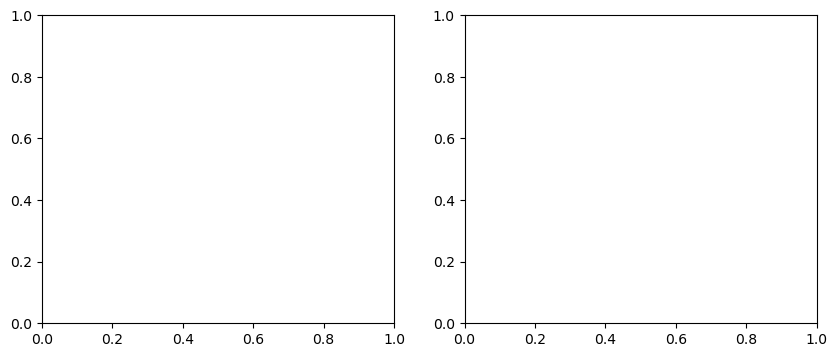

In [572]:
for oid_id in loci_ids[30:40]:
    plot_lc(oid_id)

In [181]:
a[0].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional binary table                     
NAXIS1  =                  112 / width of table in bytes                        
NAXIS2  =                 1489 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group (required keyword)              
TFIELDS =                   24 / number of fields in each row                   
TTYPE1  = 'oid     '           / label for field   1                            
TFORM1  = '1K      '           / data format of field: 8-byte INTEGER           
TTYPE2  = 'expid   '           / label for field   2                            
TFORM2  = '1J      '           / data format of field: 4-byte INTEGER           
TTYPE3  = 'hjd     '        

In [449]:
def ztf_antares_comp_lc(oid_id, filename = None):
# set up
    if filename == None:
        filename = oid_id
    fit_bands = ['zg', 'zr', 'zi']
    ant_bands = ['ztf_g', 'ztf_R', 'ztf_i']
    colors = {'ztf_g': 'green', 'ztf_R': 'maroon', 'ztf_i': 'black', 'zg': 'lime', 'zr': 'orangered', 'zi': 'blue'}
    
    a = fits.open('ztf_data/'+filename+'.fits')
    a_data = pd.DataFrame(a[1].data)
    # print(a_data)
    locus = search.get_by_id(oid_id)
    lc = lightcurve(locus.alerts)
    lc_q = lightcurve_quality(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '
    
    data_lc[oid_id] = lc
    data_lc_q[oid_id] = lc_q
    
    fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)
    #plotting ztf data
    for band in fit_bands:  
        band_lc = a_data[(a_data['filtercode'] == band)]
    
        ax[0].errorbar(band_lc['mjd'], band_lc['mag'], yerr=band_lc['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
        ax[1].errorbar(band_lc['mjd'], band_lc['mag'], yerr=band_lc['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)

    #plotting antares alert data
    for band in ant_bands:
        here_lc = lc[(lc['band'] == band)]
        here_lc_q = lc_q[(lc_q['band'] == band)]
        if len(here_lc) > 0:
            ax[0].errorbar(here_lc['mjd'], here_lc['m_sci'], yerr=here_lc['m_sci_err'], fmt='.', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
            ax[0].hlines(y=np.average(here_lc['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                           colors = colors[band], alpha = 0.3, ls = '--')
        if len(here_lc_q) > 0:
            ax[1].errorbar(here_lc_q['mjd'], here_lc_q['m_sci'], yerr=here_lc_q['m_sci_err'], fmt='.', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
            ax[1].hlines(y=np.average(here_lc_q['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                           colors = colors[band], alpha = 0.3, ls = '--')
    
    #adding flags to title
    flags = catalog_check(locus)
    for flag in flags:
        if flags[flag] == True and len(flags_str) == 7:
            flags_str += flag
        elif flags[flag] == True:
            flags_str += ', ' + flag
    if len(flags_str) > 7:
        fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(sum(lc['m_sci_flag'])) + ', ' + str(sum(lc_q['m_sci_flag'])), fontname = 'serif')
    else:
        fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(flag_n) + ', ' + str(flag_nq), fontname = 'serif')

    ax[0].set(ylim=(min(lc['m_sci'])-0.5, max(lc['m_sci'])+0.5))
    ax[1].set(ylim=(min(lc_q['m_sci'])-0.5, max(lc_q['m_sci'])+0.5))
    ax[0].yaxis.set_inverted(True)
    ax[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    plt.xlabel('MJD', fontname = 'serif')
    ax[0].set_ylabel('$mag_{AB}$', fontname = 'serif')
    ax[0].grid(alpha=0.25)
    ax[1].grid(alpha=0.25)
    plt.tight_layout()

In [567]:
def ztf_antares_comp_lc2(oid_id, filename = None):
# set up
    if filename == None:
        filename = oid_id
    fit_bands = ['zg', 'zr', 'zi']
    ant_bands = ['ztf_g', 'ztf_R', 'ztf_i']
    colors = {'ztf_g': 'green', 'ztf_R': 'maroon', 'ztf_i': 'black', 'zg': 'lime', 'zr': 'orangered', 'zi': 'blue'}
    
    a = fits.open('ztf_data/'+filename+'.fits')
    a_data = pd.DataFrame(a[1].data)
    # print(a_data)
    locus = search.get_by_id(oid_id)
    lc1, lc2 = lightcurve_quality2(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '
    
    data_lc[oid_id] = lc
    data_lc_q[oid_id] = lc_q
    
    fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=False)
    #plotting ztf data
    for band in fit_bands:  
        band_lc = a_data[(a_data['filtercode'] == band)]
    
        ax[0].errorbar(band_lc['mjd'], band_lc['mag'], yerr=band_lc['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
        ax[1].errorbar(band_lc['mjd'], band_lc['mag'], yerr=band_lc['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)

    #plotting antares alert data
    for band in ant_bands:
        here_lc1 = lc1[(lc1['band'] == band)]
        here_lc2 = lc2[(lc2['band'] == band)]
        if len(here_lc1) > 0:
            ax[0].errorbar(here_lc1['mjd'], here_lc1['m_sci'], yerr=here_lc1['m_sci_err'], fmt='.', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
            ax[0].hlines(y=np.average(here_lc['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                           colors = colors[band], alpha = 0.3, ls = '--')
        if len(here_lc2) > 0:
            ax[1].scatter(here_lc2['mjd'], here_lc2['m_sci'], s=6, c = colors[band], label=band, alpha = 0.6)
            ax[1].hlines(y=np.average(here_lc2['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                           colors = colors[band], alpha = 0.3, ls = '--')
    
    #adding flags to title
    flags = catalog_check(locus)
    for flag in flags:
        if flags[flag] == True and len(flags_str) == 7:
            flags_str += flag
        elif flags[flag] == True:
            flags_str += ', ' + flag
    if len(flags_str) > 7:
        fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(sum(lc1['m_sci_flag'])) , fontname = 'serif')
    else:
        fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(sum(lc1['m_sci_flag'])), fontname = 'serif')

    ax[0].set(ylim=(min(lc1['m_sci'])-0.5, max(lc1['m_sci'])+0.5))
    ax[1].set(ylim=(min(lc2['m_sci'])-0.5, max(lc2['m_sci'])+0.5))
    ax[0].yaxis.set_inverted(True)
    ax[1].yaxis.set_inverted(True)
    ax[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    plt.xlabel('MJD', fontname = 'serif')
    ax[0].set_ylabel('$mag_{AB}$', fontname = 'serif')
    ax[0].grid(alpha=0.25)
    ax[1].grid(alpha=0.25)
    plt.tight_layout()

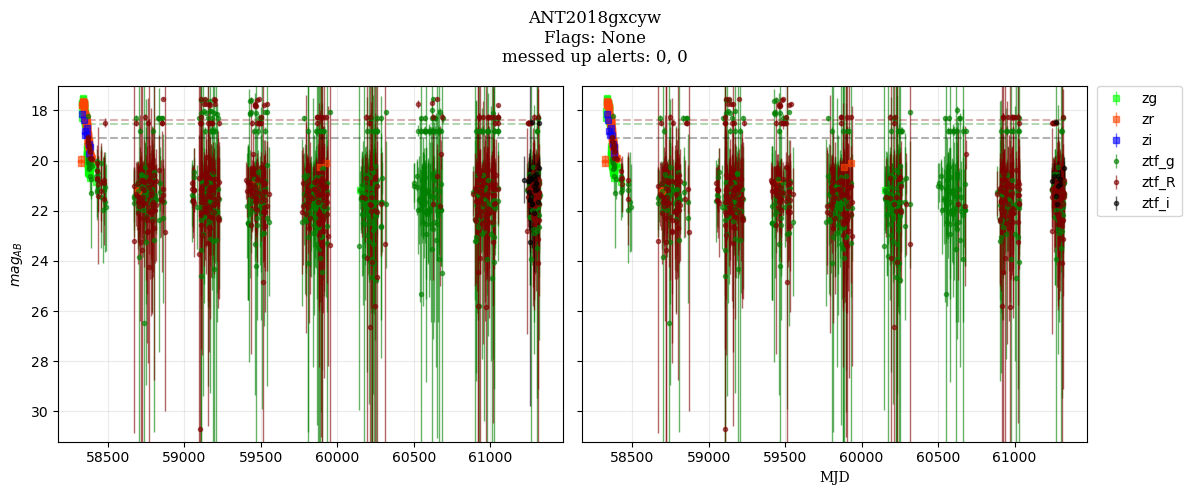

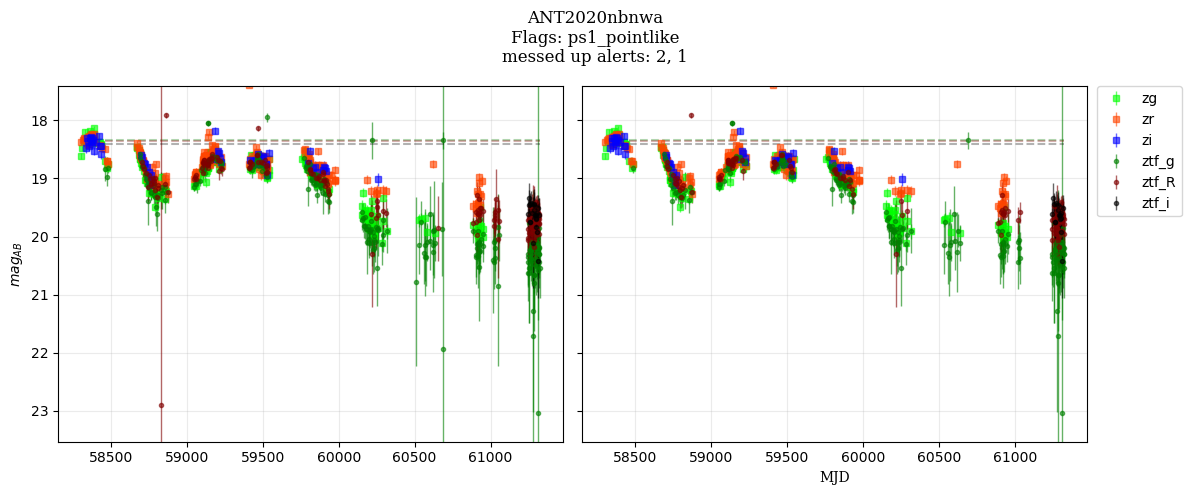

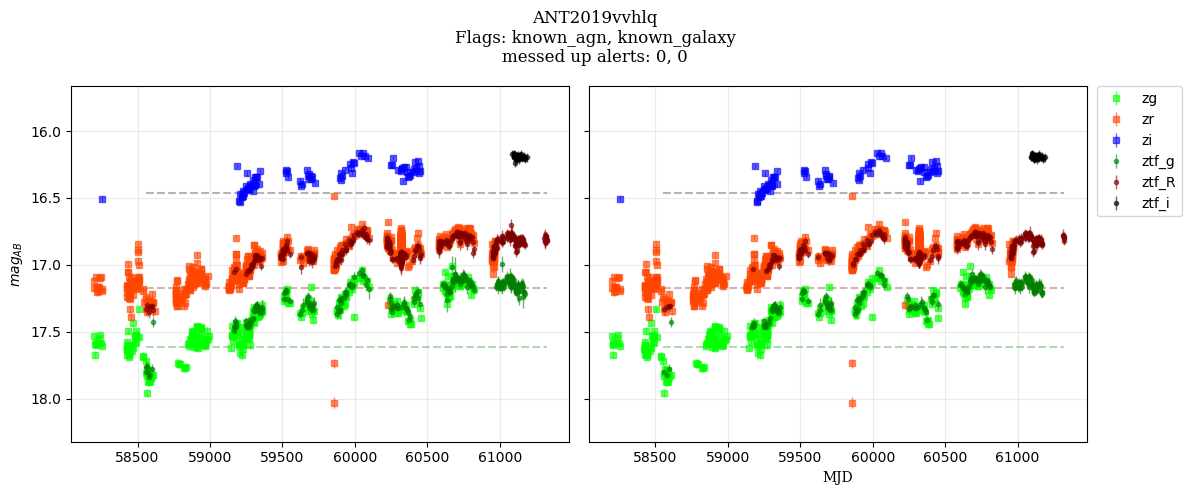

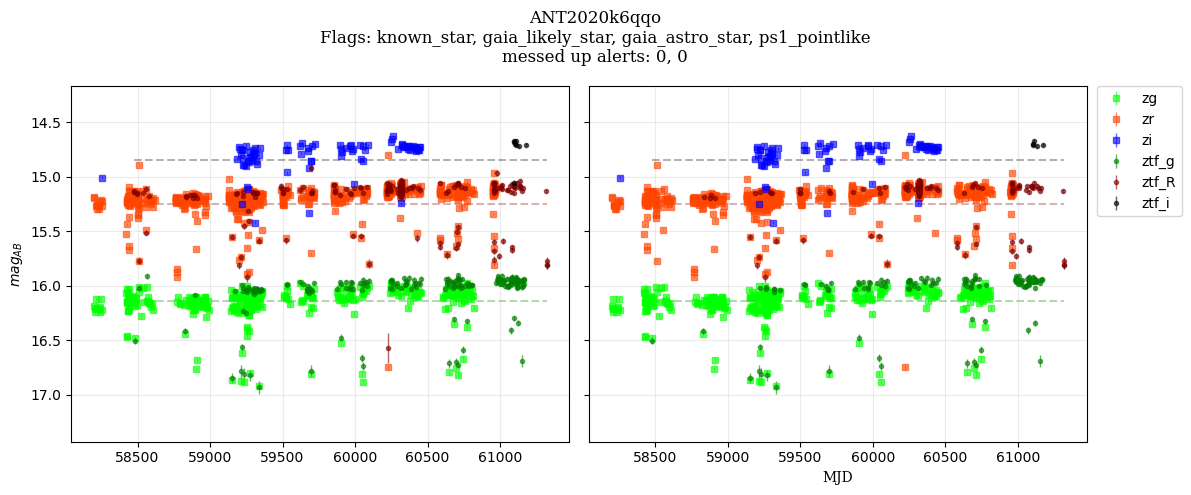

In [385]:
for oid_id in oid_ids:
    ztf_antares_comp_lc(oid_id)

8095     ANT2026rhowvgtsu67s
8113     ANT2026rhowvgtsu67s
11259    ANT2026qbj3hhuc04lm
18422    ANT2026o2wr0skd8w3h
18428    ANT2026o2wr0skd8w3h
23613    ANT2026657wad95ivmu
Name: id, dtype: object


(array([0., 0., 0., 0., 0., 6., 0., 0., 0., 0.]),
 array([-999.5, -999.4, -999.3, -999.2, -999.1, -999. , -998.9, -998.8,
        -998.7, -998.6, -998.5]),
 <BarContainer object of 10 artists>)

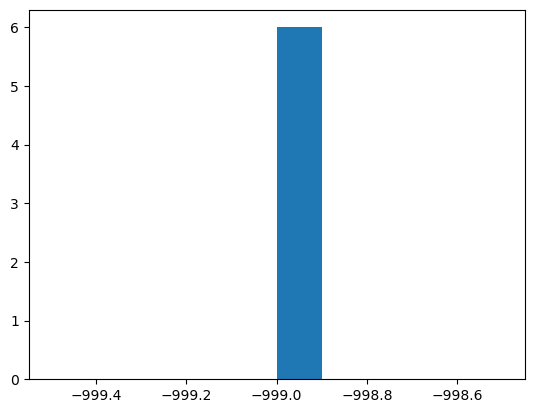

In [414]:
weird_oids = oids[(oids['m_sci'] < -50)]
# for oid_id in weird_oids['id']:
#     locus = search.get_by_id(oid_id)
    # print(f'{oid_id}\n{locus.alerts[-1].properties}\n')
# print(weird_oids['id'])
plt.hist(weird_oids['m_sci'])
# plt.semilogy()

[]

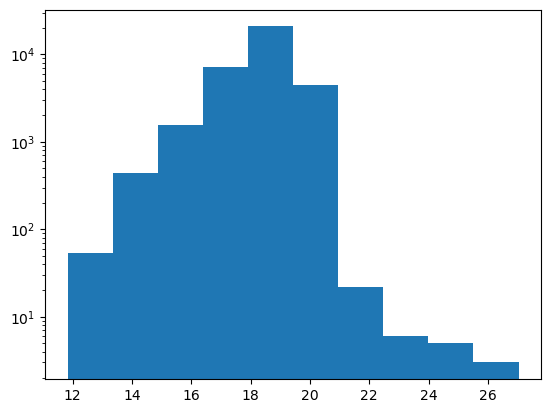

In [291]:
tame_oids = oids[(oids['m_sci'] > -50)]
plt.hist(tame_oids['m_sci'])
plt.semilogy()

In [292]:
len(oids['id'].unique())

29974

In [302]:
a = oids.sort_values(by=['id', 'mjd'])
print(a)

                        id           mjd   band      m_sci  m_sci_err  \
1861          ANT2018f3q5o  61321.246134  ztf_R  17.050207   0.039781   
12323         ANT2018f3tfe  61321.384468  ztf_g  16.831641   0.023430   
15684         ANT2018f3tkw  61321.278704  ztf_g  17.144128   0.019238   
5434          ANT2018f3vbc  61321.292882  ztf_g  17.488697   0.026934   
11052         ANT2018f3vk6  61321.334884  ztf_i  16.588985   0.026057   
...                    ...           ...    ...        ...        ...   
123    ANT2026zzl6vqatshke  61321.323171  ztf_i  17.426492   0.043468   
24339  ANT2026zzm6i18nw1iv  61321.365590  ztf_R  18.843017   0.072206   
3637   ANT2026zzy7byyihakp  61321.235174  ztf_R  18.328257   0.057025   
30780  ANT2026zzzwc9bjtuzq  61321.425845  ztf_i  18.184882   0.072943   
34138  ANT2026zzzzqfj6dk5l  61321.478634  ztf_R  18.833861   0.084986   

       m_template  m_template_err     m_diff  m_diff_err   delta_m  \
1861    16.627001           0.018  17.854670    0.062

In [321]:
lim_mag_oids = oids[(oids['m_sci'] < 20.5)]
lim_mag_oids

,id,mjd,band,m_sci,m_sci_err,m_template,m_template_err,m_diff,m_diff_err,delta_m,pos_or_neg,m_sci_flag
0,ANT20263ixwr792svim,61321.336759,ztf_i,16.794828,0.028273,22.183001,0.361,16.802448,0.028359,-5.388173,1.0,0.0
1,ANT2026e89rcy6uly2r,61321.324711,ztf_i,17.630216,0.050284,21.184999,0.148,17.672112,0.051937,-3.554783,1.0,0.0
2,ANT20265cvpk36n507o,61321.324711,ztf_i,17.391634,0.060308,22.080999,0.309,17.406185,0.060980,-4.689365,1.0,0.0
3,ANT2026dymyts7yjpj9,61321.324711,ztf_i,18.885146,0.110851,22.063000,0.318,18.944916,0.115734,-3.177854,1.0,0.0
4,ANT2026kke80pymzvg0,61321.324711,ztf_i,18.467882,0.095817,22.445999,0.355,18.496073,0.097893,-3.978117,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
34443,ANT2026ddixhrd650lh,61321.441840,ztf_i,17.809842,0.063043,22.120001,0.275,17.830534,0.064038,-4.310158,1.0,0.0
34444,ANT2026v5on6jzrpx63,61321.441840,ztf_i,17.760158,0.052522,22.493000,0.352,17.774134,0.053006,-4.732842,1.0,0.0
34445,ANT2026zoglwz0wylan,61321.441840,ztf_i,19.018403,0.113054,21.987000,0.305,19.091312,0.119036,-2.968597,1.0,0.0
34446,ANT2026gwwvkivngzj1,61321.441840,ztf_i,17.951444,0.077961,21.701000,0.200,17.986347,0.080242,-3.749556,1.0,0.0


In [584]:
j = 0
dm = lim_mag_oids[(lim_mag_oids['delta_m'] >= 1)]
bright_dm = dm[(dm['m_sci'] <= 16)]
# len(bright_dm)
dark_dm = dm[(dm['m_sci'] >= 19.5)]
len(dm)

75

In [380]:
j = 0
mid_dm = lim_mag_oids[(lim_mag_oids['delta_m'] >= 0.5)]
bright_mid_dm = dm[(dm['m_sci'] <= 16)]
# len(bright_dm)
# dark_dm = dm[(dm['m_sci'] >= 19.5)]
# len(dark_dm)
for oid_id in mid_dm['id']:
    plot_lc(oid_id)
    # plt.savefig('plots/'+oid_id+'10192026.png')

54

In [588]:
for oid_id in dm['id']:
    plot_lc(oid_id)
    plt.savefig('plots/10192026/'+oid_id+'.png')
    plt.close()

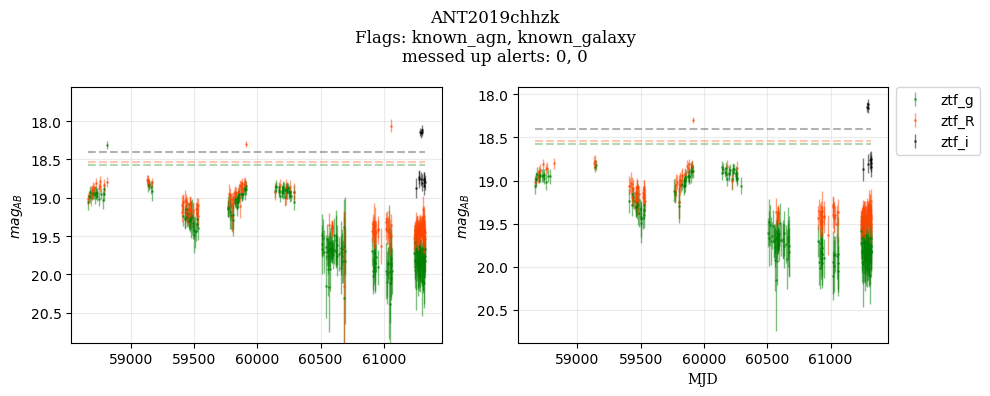

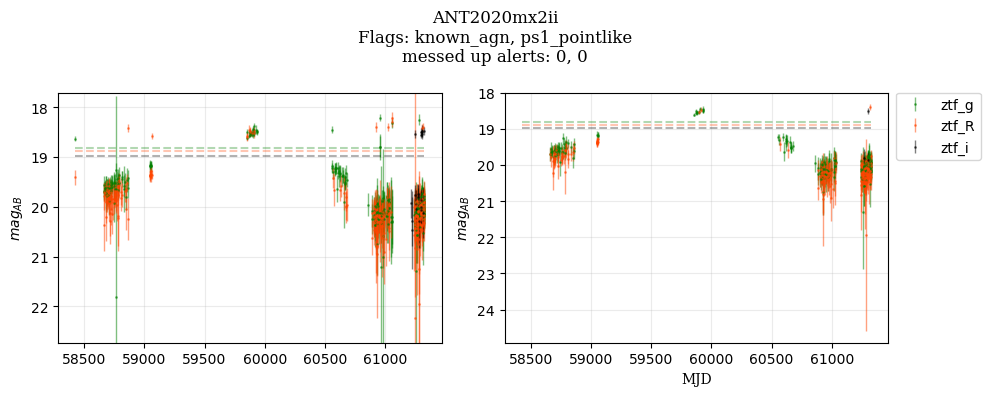

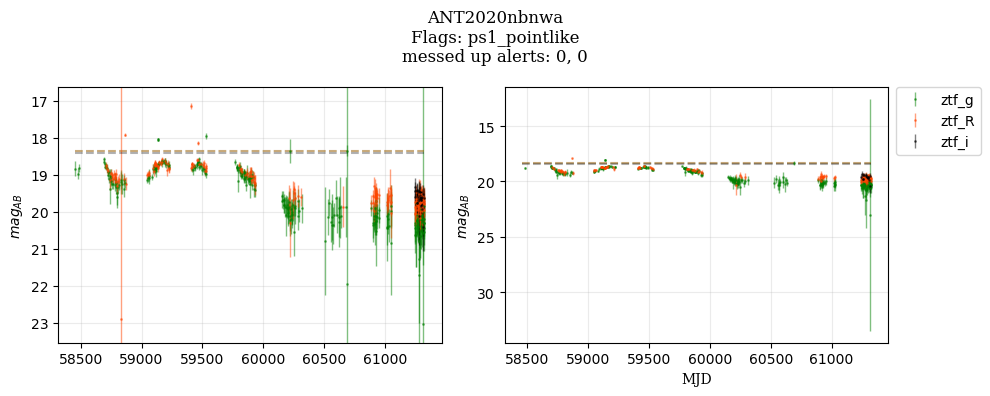

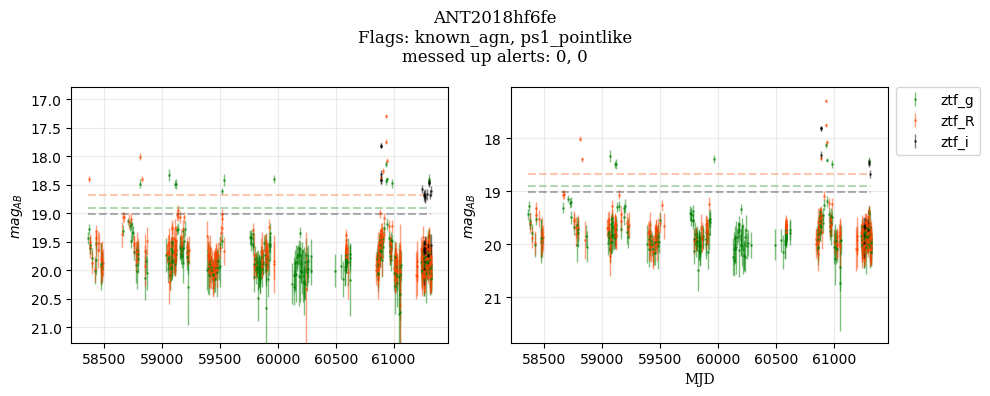

In [406]:
for oid_id in dark_dm['id'][3:7]:
    plot_lc(oid_id)
# print(j)
# j += 10

In [396]:
for oid_id in dark_dm['id'][3:5]:
    locus = search.get_by_id(oid_id)
    print(f'{oid_id}: {locus.alerts[-1].properties['ztf_ra']} {locus.alerts[-1].properties['ztf_dec']}')
    # print(locus.alerts[-1].properties)

ANT2019chhzk: 9.8816036 -11.1839957
ANT2020mx2ii: 5.3198753 -19.8199142


UnboundLocalError: cannot access local variable 'max_lc' where it is not associated with a value

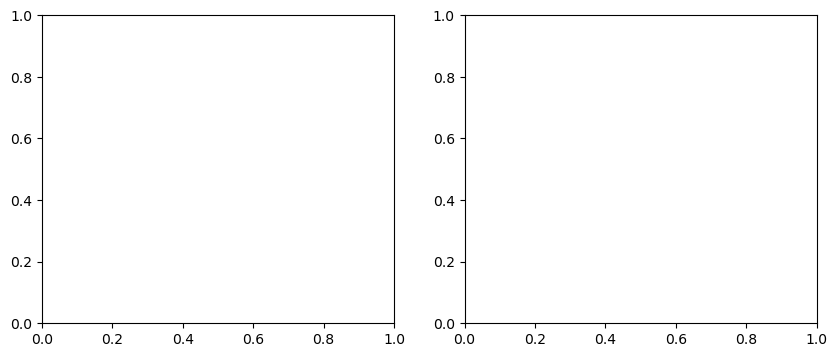

In [570]:
for oid_id in bright_dm['id']:
    plot_lc(oid_id)

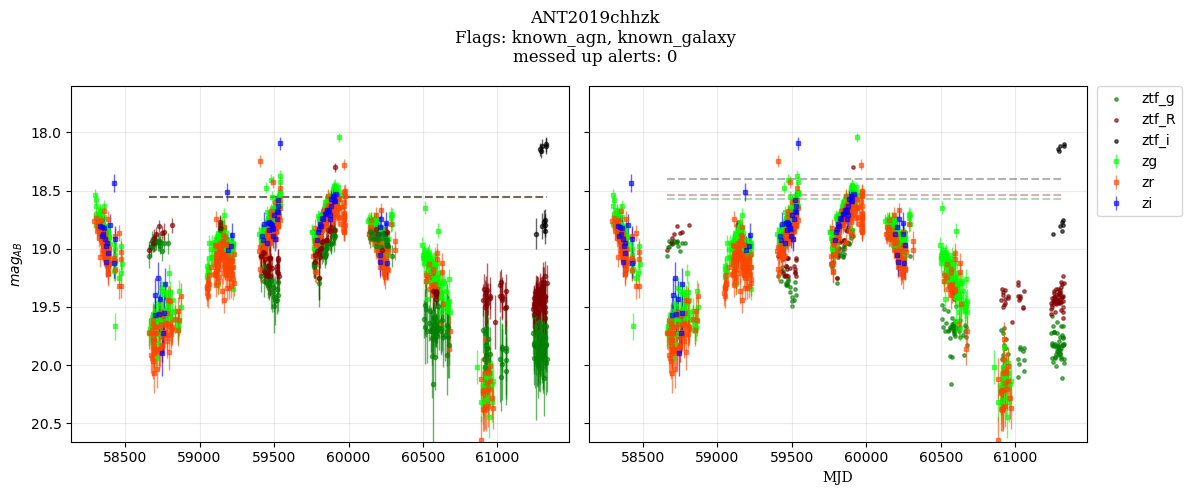

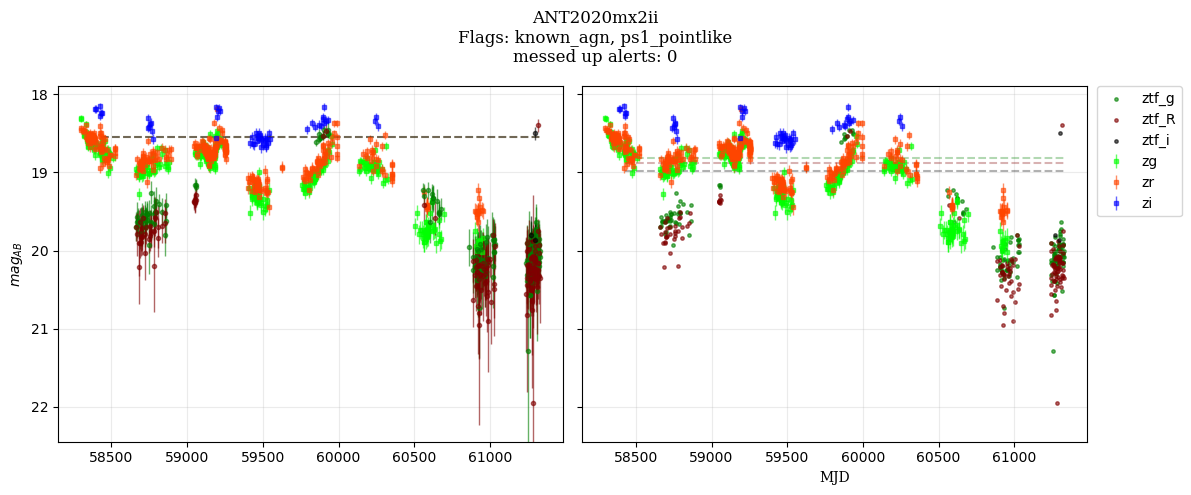

In [554]:
for oid_id in dark_dm['id'][3:5]:
    ztf_antares_comp_lc2(oid_id)
    ztf_antares_comp_lc2(oid_id)

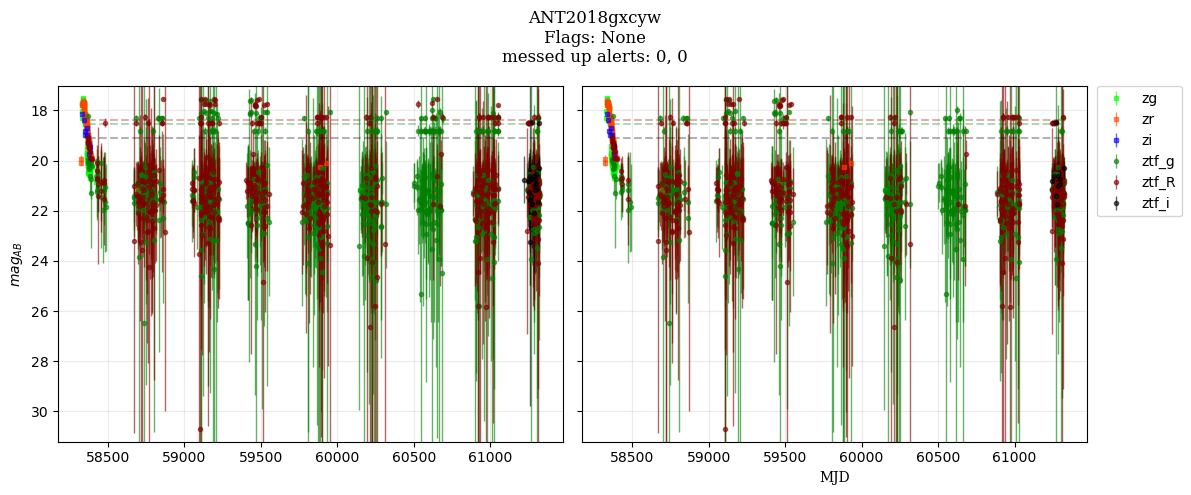

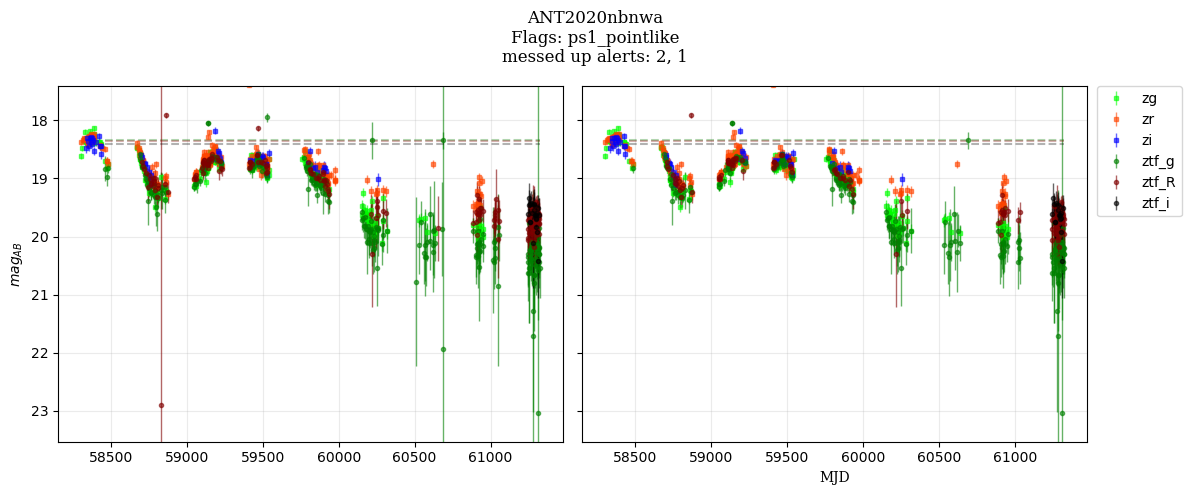

In [405]:
for oid_id in too_dark_oids:
    ztf_antares_comp_lc(oid_id)

In [525]:
def ztf_ant_direct_comp(oid_id, filename = None): #only quality ant data
# set up
    if filename == None:
        filename = oid_id
    fit_bands = ['zg', 'zr', 'zi']
    ant_bands = ['ztf_g', 'ztf_R', 'ztf_i']
    colors = {'ztf_g': 'green', 'ztf_R': 'maroon', 'ztf_i': 'black', 'zg': 'lime', 'zr': 'orangered', 'zi': 'blue'}
    
    a = fits.open('ztf_data/'+filename+'.fits')
    a_data = pd.DataFrame(a[1].data)
    # print(a_data)
    locus = search.get_by_id(oid_id)
    lc = lightcurve_quality(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '

    fig, ax = plt.subplots(1,1, figsize=(8,5))
    ax1 = ax.twinx()
    #plotting ztf data
    for band in fit_bands:  
        band_lc = a_data[(a_data['filtercode'] == band)]
        ax.errorbar(band_lc['mjd'], band_lc['mag'], yerr=band_lc['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], 
                    label='ztf '+band, alpha = 0.6)
        
    #plotting antares alert data
    for band in ant_bands:
        here_lc = lc[(lc['band'] == band)]
        here_lc_p = here_lc[(here_lc['pos_or_neg'] > 0)]
        here_lc_n = here_lc[(here_lc['pos_or_neg'] < 0)]
        m = 10.**(0.4*(here_lc['m_template'] - here_lc['m_diff']))
        # ax.errorbar(here_lc['mjd'], here_lc['m_sci'], yerr=here_lc['m_sci_err'], fmt='.', ms=6, lw=1, c = colors[band], ecolor = colors[band], label='m_sci '+band, alpha = 0.6)
        ax.errorbar(here_lc_p['mjd'], here_lc_p['m_diff'], yerr=here_lc_p['m_diff_err'], fmt='^', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=r"$\Delta m$ "+band+' ^', alpha = 0.6)
        ax.errorbar(here_lc_n['mjd'], here_lc_n['m_diff'], yerr=here_lc_n['m_diff_err'], fmt='v', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=r"$\Delta m$"+band+' v', alpha = 0.6)
        # print(m)
        ax1.plot(here_lc['mjd'], m, c = colors[band], alpha = 0.3, ls = ':')
        ax.plot(here_lc['mjd'], here_lc['m_template'], c = colors[band], alpha = 0.3, ls = '--')
        
    #adding flags to title
    flags = catalog_check(locus)
    for flag in flags:
        if flags[flag] == True and len(flags_str) == 7:
            flags_str += flag
        elif flags[flag] == True:
            flags_str += ', ' + flag
    if len(flags_str) > 7:
        fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(sum(lc['m_sci_flag'])), fontname = 'serif')
    else:
        fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(flag_n), fontname = 'serif')

    

    ax.set(ylim=(min(lc['m_sci'])-0.5, max(lc['m_sci'])+0.5))
    ax.yaxis.set_inverted(True)
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    plt.xlabel('MJD', fontname = 'serif')
    ax.set_ylabel('$mag_{AB}$', fontname = 'serif')
    ax.grid(alpha=0.25)
    plt.tight_layout()

In [537]:
def ztf_catflags(oid_id, filename = None):
# set up
    if filename == None:
        filename = oid_id
    fit_bands = ['zg', 'zr', 'zi']
    ant_bands = ['ztf_g', 'ztf_R', 'ztf_i']
    colors = {'ztf_g': 'green', 'ztf_R': 'maroon', 'ztf_i': 'black', 'zg': 'lime', 'zr': 'orangered', 'zi': 'blue'}
    
    a = fits.open('ztf_data/'+filename+'.fits')
    a_data = pd.DataFrame(a[1].data)
    a_data_cat = a_data[(a_data['catflags'] == 0)]
    locus = search.get_by_id(oid_id)
    lc = lightcurve_quality(locus.alerts)
    title = oid_id
    flags_str = 'Flags: '
    
    fig, ax = plt.subplots(1,2, figsize=(12,5), sharey=True)
    #plotting ztf data
    for band in fit_bands:  
        band_lc = a_data[(a_data['filtercode'] == band)]
        band_lc_cat = a_data_cat[(a_data_cat['filtercode'] == band)]
    
        ax[0].errorbar(band_lc['mjd'], band_lc['mag'], yerr=band_lc['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
        ax[1].errorbar(band_lc_cat['mjd'], band_lc_cat['mag'], yerr=band_lc_cat['magerr'], fmt='s', ms=3, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)

    #plotting antares alert data
    for band in ant_bands:
        here_lc = lc[(lc['band'] == band)]
        if len(here_lc) > 0:
            ax[0].errorbar(here_lc['mjd'], here_lc['m_sci'], yerr=here_lc['m_sci_err'], fmt='.', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
            ax[0].hlines(y=np.average(here_lc['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                           colors = colors[band], alpha = 0.3, ls = '--')
            ax[1].errorbar(here_lc['mjd'], here_lc['m_sci'], yerr=here_lc['m_sci_err'], fmt='.', ms=6, lw=1, c = colors[band], ecolor = colors[band], label=band, alpha = 0.6)
            ax[1].hlines(y=np.average(here_lc['m_template']), xmin = locus.properties['oldest_alert_observation_time'], xmax= locus.properties['newest_alert_observation_time'], 
                           colors = colors[band], alpha = 0.3, ls = '--')
        
    #adding flags to title
    flags = catalog_check(locus)
    for flag in flags:
        if flags[flag] == True and len(flags_str) == 7:
            flags_str += flag
        elif flags[flag] == True:
            flags_str += ', ' + flag
    if len(flags_str) > 7:
        fig.suptitle(title + '\n' + flags_str + '\nmessed up alerts: ' + str(sum(lc['m_sci_flag'])), fontname = 'serif')
    else:
        fig.suptitle(title + '\n' + flags_str + 'None\nmessed up alerts: ' + str(flag_n), fontname = 'serif')

    ax[0].set(ylim=(min(lc['m_sci'])-0.5, max(lc['m_sci'])+0.5))
    ax[0].yaxis.set_inverted(True)
    ax[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
    plt.xlabel('MJD', fontname = 'serif')
    ax[0].set_ylabel('$mag_{AB}$', fontname = 'serif')
    ax[0].grid(alpha=0.25)
    ax[1].grid(alpha=0.25)
    plt.tight_layout()

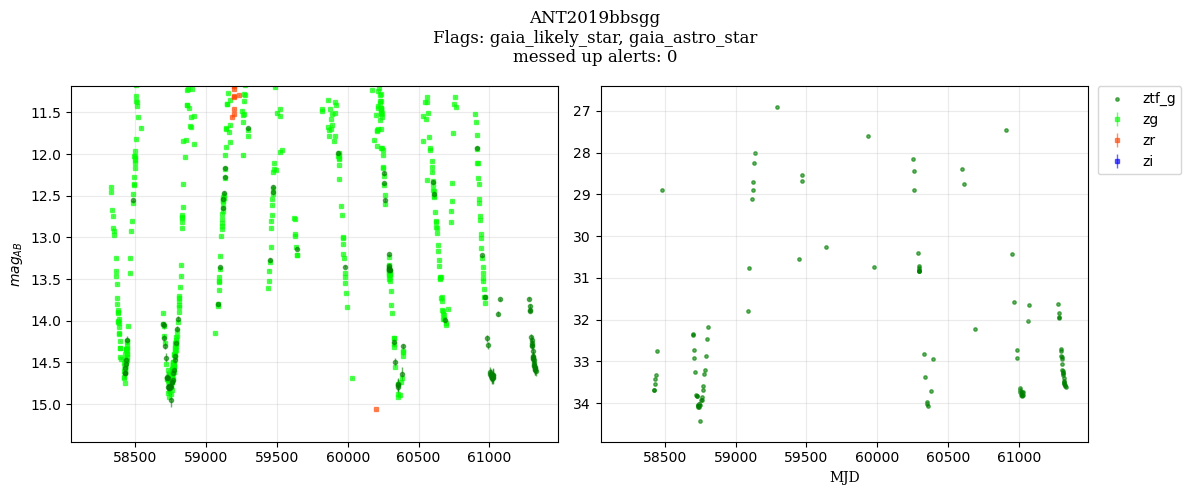

In [569]:
# ztf_ant_direct_comp('ANT2019chhzk')
# ztf_catflags('ANT2019chhzk')
ztf_antares_comp_lc2('ANT2019bbsgg')

In [564]:
locus = search.get_by_id('ANT2019chhzk')
for alert in locus.alerts:
    if alert.properties['ant_survey'] == 1:
        ztf_pass = ztf_quality(alert)
        if ztf_pass == True:
            calc1 = ztf_alert(alert)
            calc2 = ztf_alert2(alert)
        # if abs(calc1['m_sci'] - calc2['m_sci']) >= 10**-2:
        print(f'1: {calc1['m_sci']}, 2: {calc2['m_sci']}')

1: 19.06055513214322, 2: 43.88855011146414
1: 19.01157619517089, 2: 43.77577194132094
1: 18.982519410424366, 2: 43.70886622191327
1: 18.985109960989824, 2: 43.71483118502794
1: 18.929502587522716, 2: 43.58679047582203
1: 18.929502587522716, 2: 43.58679047582203
1: 18.95406656461341, 2: 43.6433511232957
1: 18.957738349252654, 2: 43.651805719870715
1: 18.90399242599697, 2: 43.52805115817297
1: 18.945397544804337, 2: 43.623389967512466
1: 18.949875666624585, 2: 43.63370122406038
1: 18.949875666624585, 2: 43.63370122406038
1: 18.93546809941176, 2: 43.60052657456982
1: 18.87615858805571, 2: 43.46396137784861
1: 18.87615858805571, 2: 43.46396137784861
1: 18.944862381592547, 2: 43.62215770867867
1: 18.803486581260945, 2: 43.29662789832503
1: 18.93522852535028, 2: 43.59997493490718
1: 18.938917856385306, 2: 43.60846993355156
1: 18.972797910963415, 2: 43.686481642172936
1: 18.867297239006835, 2: 43.44355736762486
1: 19.016365033691176, 2: 43.78679864951052
1: 19.016365033691176, 2: 43.786798649

In [589]:
oids

,id,mjd,band,m_sci,m_sci_err,m_template,m_template_err,m_diff,m_diff_err,delta_m,pos_or_neg,m_sci_flag
0,ANT20263ixwr792svim,61321.336759,ztf_i,16.794828,0.028273,22.183001,0.361,16.802448,0.028359,-5.388173,1.0,0.0
1,ANT2026e89rcy6uly2r,61321.324711,ztf_i,17.630216,0.050284,21.184999,0.148,17.672112,0.051937,-3.554783,1.0,0.0
2,ANT20265cvpk36n507o,61321.324711,ztf_i,17.391634,0.060308,22.080999,0.309,17.406185,0.060980,-4.689365,1.0,0.0
3,ANT2026dymyts7yjpj9,61321.324711,ztf_i,18.885146,0.110851,22.063000,0.318,18.944916,0.115734,-3.177854,1.0,0.0
4,ANT2026kke80pymzvg0,61321.324711,ztf_i,18.467882,0.095817,22.445999,0.355,18.496073,0.097893,-3.978117,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
34443,ANT2026ddixhrd650lh,61321.441840,ztf_i,17.809842,0.063043,22.120001,0.275,17.830534,0.064038,-4.310158,1.0,0.0
34444,ANT2026v5on6jzrpx63,61321.441840,ztf_i,17.760158,0.052522,22.493000,0.352,17.774134,0.053006,-4.732842,1.0,0.0
34445,ANT2026zoglwz0wylan,61321.441840,ztf_i,19.018403,0.113054,21.987000,0.305,19.091312,0.119036,-2.968597,1.0,0.0
34446,ANT2026gwwvkivngzj1,61321.441840,ztf_i,17.951444,0.077961,21.701000,0.200,17.986347,0.080242,-3.749556,1.0,0.0


In [591]:
a = oids['m_sci'] - oids['m_template']
a

0       -5.388173
1       -3.554783
2       -4.689365
3       -3.177854
4       -3.978117
           ...   
34443   -4.310158
34444   -4.732842
34445   -2.968597
34446   -3.749556
34447   -2.543337
Length: 34448, dtype: float64

In [ ]:

thresh = pd.DataFrame(columns = ['threshold', 'count', 'pass/good qual%', 'pass/total%', 'trig alerts/sr', 'trig alerts/f_low', 'trig alerts/f_high'])
ts = np.arange(0.1, 1.1,0.1)
for t in ts:
    sr1 = 10*(np.pi*0.5/180)**2
    sr2 = 10*(np.pi*0.75/180)**2
    count = sum(abs(v) > t for v in a)
    good_quality_p = float(100*count/len(hv))
    tot_p = float(100*count/checked_61289)
    density = count/(13*(np.pi**2)/18)
    thresh.loc[t-1] = [t, count, good_quality_p, tot_p, density, density*sr1, density*sr2]
    # print(f'note: these numbers come from using 75% of sky from observations on 09/05/26\nthreshold, % from good data, % from total query\n')
thresh  
# print(sr1*100/(13*(np.pi/18)**2), sr2*100/(13*(np.pi**2)/18))